# CIPHER — Full Corpus Model Evaluation

Standalone evaluation of the **`models_full/`** checkpoint trained on 71,262 documents  
(32 features · VotingClassifier GBM+LR · test set: 15,272 docs from `data/full/test.csv`)

| Section | Content |
|---------|--------|
| 1 | Setup & model loading |
| 2 | Feature extraction from test set |
| 3 | Core metrics + bootstrap CI |
| 4 | ROC & PR curves |
| 5 | Confusion matrix |
| 6 | Score distribution |
| 7 | Feature importances (GBM) |
| 8 | Calibration |
| 9 | Error analysis |
| 10 | Summary |

## 1 · Setup & Model Loading

In [1]:
import sys, os, pickle, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
warnings.filterwarnings("ignore")

from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    accuracy_score, f1_score, precision_score, recall_score,
    roc_curve, precision_recall_curve,
    confusion_matrix, classification_report,
)
from sklearn.calibration import calibration_curve

# ── Paths ─────────────────────────────────────────────────────────────────────
ROOT      = Path(os.getcwd()).resolve().parent
MODEL_DIR = ROOT / "models_full"
TEST_CSV  = ROOT / "data" / "full" / "test.csv"
CIPHER_SRC = str(ROOT / "cipher")
FIG_DIR   = Path(".")          # save figures alongside notebook

if CIPHER_SRC not in sys.path:
    sys.path.insert(0, CIPHER_SRC)

# ── Verify model exists ───────────────────────────────────────────────────────
pkl = MODEL_DIR / "meta_learner.pkl"
assert pkl.exists(), f"Model not found: {pkl}"
with open(pkl, "rb") as f:
    STATE = pickle.load(f)

SCALER = STATE["scaler"]
CLF    = STATE["sklearn_model"]
N_FEAT = SCALER.n_features_in_

print(f"Model loaded from : {MODEL_DIR}")
print(f"Classifier        : {type(CLF).__name__}")
print(f"Features expected : {N_FEAT}")
print(f"Python            : {sys.version.split()[0]}")


Model loaded from : /Users/levent.ozparlak/Projects/AITextDetection/models_full
Classifier        : VotingClassifier
Features expected : 32
Python            : 3.14.4


## 2 · Feature Extraction from Test Set

Extracts all 32 CIPHER features for every document in `data/full/test.csv`.
This takes ~20–30 minutes on first run. The result is cached to `full_test_features.npz`.

In [2]:
import csv, time
import spacy
from cipher.layers.compression import compute_compression_features
from cipher.layers.cognitive   import compute_cognitive_features
from cipher.layers.discourse   import compute_discourse_features
from cipher.layers.lexical     import compute_lexical_features
from cipher.layers.assembler   import FeatureVector

CACHE = ROOT / "data" / "full_test_features.npz"

if CACHE.exists():
    print(f"Loading cached features from {CACHE} …")
    npz    = np.load(CACHE, allow_pickle=True)
    X_test = npz["X"].astype(np.float64)
    y_test = npz["y"]
    texts  = list(npz["texts"])
    print(f"  X_test shape : {X_test.shape}  dtype={X_test.dtype}")
else:
    print("Loading spaCy model …")
    nlp = spacy.load("en_core_web_sm")

    print(f"Reading {TEST_CSV} …")
    rows = []
    with open(TEST_CSV) as f:
        for row in csv.DictReader(f):
            t = row.get("text", "").strip()
            l = int(row.get("label", -1))
            if t and l in (0, 1):
                rows.append((t, l))
    texts  = [r[0] for r in rows]
    labels = [r[1] for r in rows]
    print(f"  {len(texts):,} test documents")

    X_list = []
    t0 = time.time()
    for i, text in enumerate(texts):
        if (i + 1) % 500 == 0:
            elapsed = time.time() - t0
            eta = elapsed / (i + 1) * (len(texts) - i - 1)
            print(f"  {i+1:>6,}/{len(texts):,}  elapsed={elapsed/60:.1f}m  ETA={eta/60:.1f}m")
        comp = compute_compression_features(text)
        cog  = compute_cognitive_features(text)
        disc = compute_discourse_features(text, nlp=nlp)
        lex  = compute_lexical_features(text, nlp=nlp)
        fv   = FeatureVector(compression=comp, cognitive=cog, discourse=disc, lexical=lex)
        X_list.append(fv.to_array(include_manifold=False))

    X_test = np.array(X_list, dtype=np.float64)
    y_test = np.array(labels, dtype=np.int32)
    np.savez_compressed(CACHE, X=X_test, y=y_test, texts=np.array(texts, dtype=object))
    print(f"\nSaved cache → {CACHE}")
    print(f"X_test shape : {X_test.shape}  dtype={X_test.dtype}")

assert X_test.shape[1] == N_FEAT, f"Feature mismatch: got {X_test.shape[1]}, model expects {N_FEAT}"
print(f"\nReady: {X_test.shape[0]:,} docs × {X_test.shape[1]} features")


Loading spaCy model …


Reading /Users/levent.ozparlak/Projects/AITextDetection/data/full/test.csv …


  19,099 test documents


     500/19,099  elapsed=1.1m  ETA=41.6m


   1,000/19,099  elapsed=2.2m  ETA=40.0m


   1,500/19,099  elapsed=3.3m  ETA=38.2m


... (32 outputs left out)

  18,000/19,099  elapsed=37.2m  ETA=2.3m


  18,500/19,099  elapsed=38.2m  ETA=1.2m


  19,000/19,099  elapsed=39.2m  ETA=0.2m



Saved cache → /Users/levent.ozparlak/Projects/AITextDetection/data/full_test_features.npz
X_test shape : (19099, 32)  dtype=float64

Ready: 19,099 docs × 32 features


## 3 · Core Metrics

In [3]:
# ── Predict ───────────────────────────────────────────────────────────────────
X_clean = np.nan_to_num(X_test, nan=0.0, posinf=5.0, neginf=-5.0)
X_s     = SCALER.transform(X_clean)
y_prob  = CLF.predict_proba(X_s)[:, 1]
y_pred  = (y_prob >= 0.5).astype(int)

# ── Bootstrap CI ─────────────────────────────────────────────────────────────
def bootstrap_ci(y_true, y_score, metric_fn, n_boot=1000, alpha=0.05, **kw):
    rng = np.random.default_rng(42)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), size=len(y_true))
        try:
            vals.append(metric_fn(y_true[idx], y_score[idx], **kw))
        except Exception:
            pass
    lo = np.percentile(vals, 100 * alpha / 2)
    hi = np.percentile(vals, 100 * (1 - alpha / 2))
    return float(np.mean(vals)), float(lo), float(hi)

roc_auc  = roc_auc_score(y_test, y_prob)
pr_auc   = average_precision_score(y_test, y_prob)
acc      = accuracy_score(y_test, y_pred)
prec     = precision_score(y_test, y_pred, zero_division=0)
rec      = recall_score(y_test, y_pred, zero_division=0)
f1       = f1_score(y_test, y_pred, zero_division=0)

_, auc_lo, auc_hi = bootstrap_ci(y_test, y_prob, roc_auc_score)
_, pr_lo,  pr_hi  = bootstrap_ci(y_test, y_prob, average_precision_score)

print("=" * 52)
print(" CIPHER Full Corpus Model — Test Set Results")
print("=" * 52)
print(f"  Docs evaluated   : {len(y_test):,}")
print(f"  ROC-AUC          : {roc_auc:.4f}  95% CI [{auc_lo:.3f} – {auc_hi:.3f}]")
print(f"  PR-AUC           : {pr_auc:.4f}  95% CI [{pr_lo:.3f} – {pr_hi:.3f}]")
print(f"  Accuracy         : {acc:.4f}")
print(f"  Precision (AI)   : {prec:.4f}")
print(f"  Recall    (AI)   : {rec:.4f}")
print(f"  F1        (AI)   : {f1:.4f}")
print("=" * 52)

 CIPHER Full Corpus Model — Test Set Results
  Docs evaluated   : 19,099
  ROC-AUC          : 0.9432  95% CI [0.940 – 0.946]
  PR-AUC           : 0.9467  95% CI [0.943 – 0.950]
  Accuracy         : 0.8700
  Precision (AI)   : 0.8804
  Recall    (AI)   : 0.8674
  F1        (AI)   : 0.8739


## 4 · ROC & PR Curves

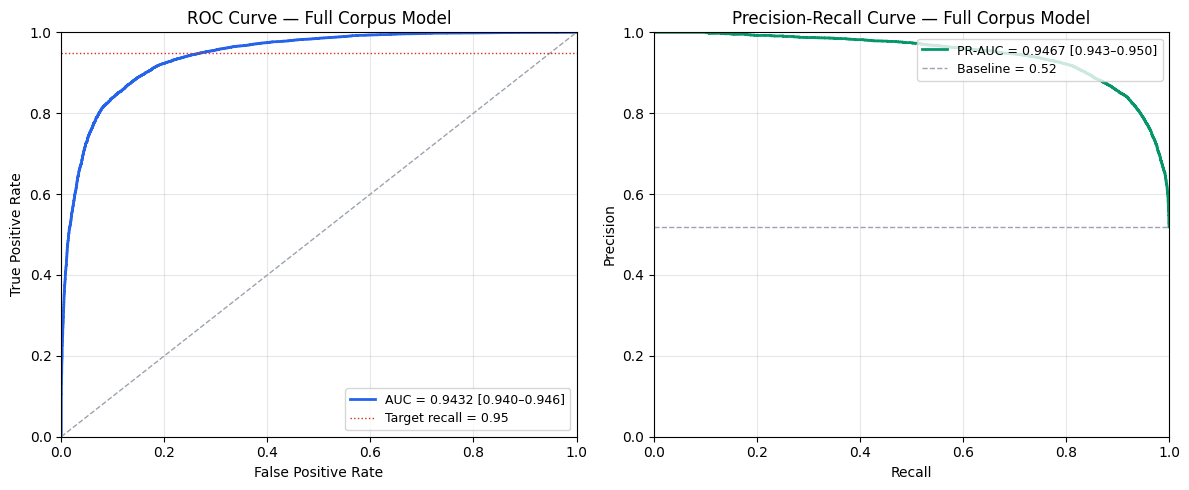

Figure saved.


In [4]:
fpr, tpr, _     = roc_curve(y_test, y_prob)
prec_c, rec_c, _ = precision_recall_curve(y_test, y_prob)
baseline_pr      = y_test.mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# ROC
ax1.plot(fpr, tpr, lw=2, color="#2563EB",
         label=f"AUC = {roc_auc:.4f} [{auc_lo:.3f}–{auc_hi:.3f}]")
ax1.plot([0, 1], [0, 1], "--", color="#9CA3AF", lw=1)
ax1.axhline(0.95, color="#DC2626", lw=1, ls=":", label="Target recall = 0.95")
ax1.set(xlabel="False Positive Rate", ylabel="True Positive Rate",
        title="ROC Curve — Full Corpus Model", xlim=(0, 1), ylim=(0, 1))
ax1.legend(loc="lower right", fontsize=9)
ax1.grid(alpha=0.3)

# PR
ax2.plot(rec_c, prec_c, lw=2, color="#059669",
         label=f"PR-AUC = {pr_auc:.4f} [{pr_lo:.3f}–{pr_hi:.3f}]")
ax2.axhline(baseline_pr, color="#9CA3AF", lw=1, ls="--",
            label=f"Baseline = {baseline_pr:.2f}")
ax2.set(xlabel="Recall", ylabel="Precision",
        title="Precision-Recall Curve — Full Corpus Model", xlim=(0, 1), ylim=(0, 1))
ax2.legend(loc="upper right", fontsize=9)
ax2.grid(alpha=0.3)

plt.tight_layout()
fig.savefig(FIG_DIR / "full_model_roc_pr.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure saved.")

## 5 · Confusion Matrix

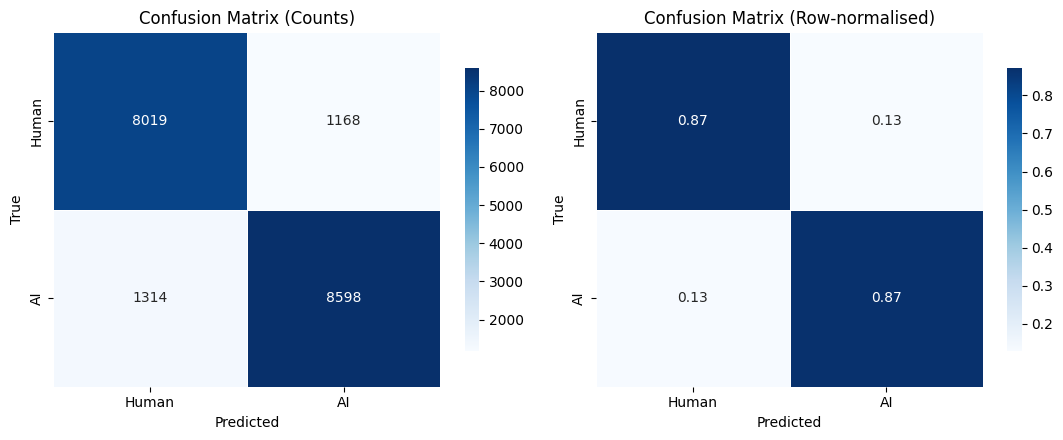

              precision    recall  f1-score   support

       Human       0.86      0.87      0.87      9187
          AI       0.88      0.87      0.87      9912

    accuracy                           0.87     19099
   macro avg       0.87      0.87      0.87     19099
weighted avg       0.87      0.87      0.87     19099



In [5]:
cm   = confusion_matrix(y_test, y_pred)
cm_n = cm.astype(float) / cm.sum(axis=1, keepdims=True)   # row-normalised

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
labels = ["Human", "AI"]

for ax, data, fmt, title in [
    (ax1, cm,   "d",    "Counts"),
    (ax2, cm_n, ".2f",  "Row-normalised"),
]:
    sns.heatmap(data, annot=True, fmt=fmt, cmap="Blues", ax=ax,
                xticklabels=labels, yticklabels=labels,
                linewidths=0.5, linecolor="white",
                cbar_kws={"shrink": 0.8})
    ax.set(xlabel="Predicted", ylabel="True",
           title=f"Confusion Matrix ({title})")

plt.tight_layout()
fig.savefig(FIG_DIR / "full_model_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

print(classification_report(y_test, y_pred, target_names=["Human", "AI"]))

## 6 · Score Distribution

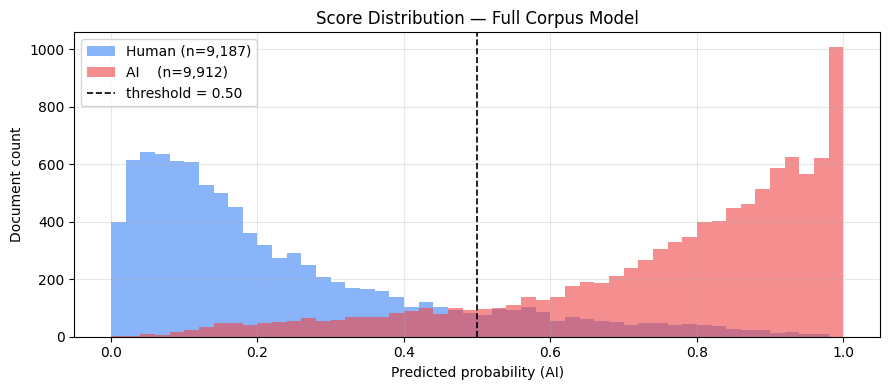

Figure saved.


In [6]:
fig, ax = plt.subplots(figsize=(9, 4))

bins = np.linspace(0, 1, 51)
ax.hist(y_prob[y_test == 0], bins=bins, alpha=0.6, color="#3B82F6",
        label=f"Human (n={( y_test==0).sum():,})")
ax.hist(y_prob[y_test == 1], bins=bins, alpha=0.6, color="#EF4444",
        label=f"AI    (n={(y_test==1).sum():,})")
ax.axvline(0.5, color="black", lw=1.2, ls="--", label="threshold = 0.50")
ax.set(xlabel="Predicted probability (AI)", ylabel="Document count",
       title="Score Distribution — Full Corpus Model")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(FIG_DIR / "full_model_score_dist.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure saved.")

## 7 · Feature Importances (GBM sub-estimator)

Computing permutation importances (n_repeats=10) ...


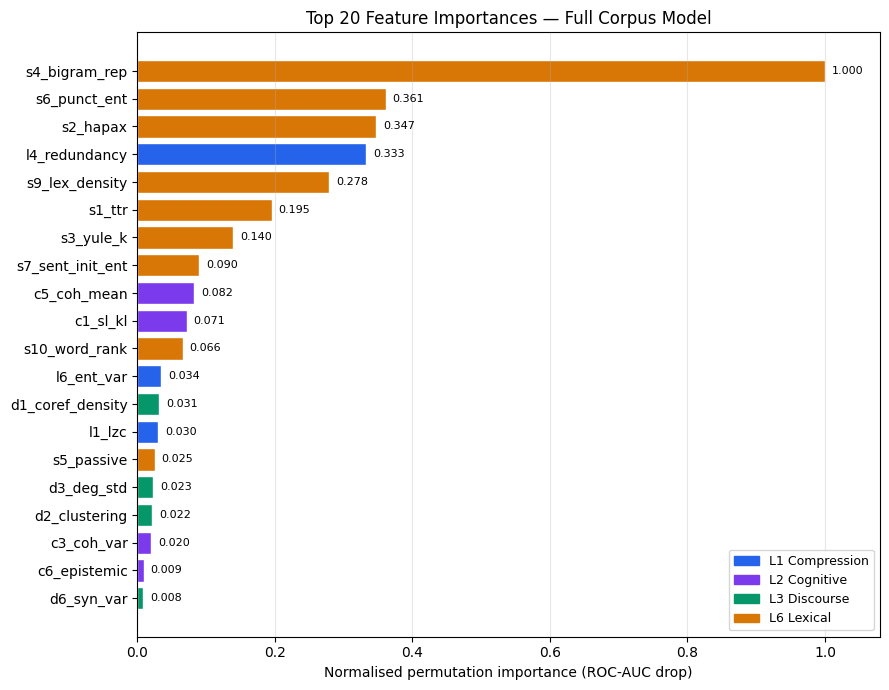

Top 10:
  s4_bigram_rep              1.0000
  s6_punct_ent               0.3612
  s2_hapax                   0.3469
  l4_redundancy              0.3327
  s9_lex_density             0.2784
  s1_ttr                     0.1950
  s3_yule_k                  0.1396
  s7_sent_init_ent           0.0900
  c5_coh_mean                0.0824
  c1_sl_kl                   0.0713


In [7]:
from cipher.layers.assembler import FeatureVector
from sklearn.inspection import permutation_importance

FEAT_NAMES = [n for n in FeatureVector.FEATURE_NAMES if n != "m1_manifold"]
assert len(FEAT_NAMES) == N_FEAT, f"{len(FEAT_NAMES)} names vs {N_FEAT} features"

# Permutation importance on the full VotingClassifier
print("Computing permutation importances (n_repeats=10) ...")
pi = permutation_importance(CLF, X_s, y_test, n_repeats=10,
                            scoring="roc_auc", random_state=42, n_jobs=-1)
raw = pi.importances_mean
imp = (raw - raw.min()) / (raw.max() - raw.min())   # normalise to [0, 1]

imp_df = pd.DataFrame({"feature": FEAT_NAMES, "importance": imp})\
           .sort_values("importance", ascending=False)

TOP_N = 20
top = imp_df.head(TOP_N).sort_values("importance")

layer_colors = {
    "l": "#2563EB",
    "c": "#7C3AED",
    "d": "#059669",
    "s": "#D97706",
}
bar_colors = [layer_colors.get(f[0], "#6B7280") for f in top["feature"]]

fig, ax = plt.subplots(figsize=(9, 7))
bars = ax.barh(top["feature"], top["importance"], color=bar_colors, edgecolor="white")
ax.set(xlabel="Normalised permutation importance (ROC-AUC drop)",
       title=f"Top {TOP_N} Feature Importances — Full Corpus Model",
       xlim=(0, 1.08))
for bar, val in zip(bars, top["importance"]):
    ax.text(val + 0.01, bar.get_y() + bar.get_height() / 2,
            f"{val:.3f}", va="center", fontsize=8)

from matplotlib.patches import Patch
legend_handles = [Patch(color=c, label=lbl) for lbl, c in [
    ("L1 Compression", "#2563EB"), ("L2 Cognitive", "#7C3AED"),
    ("L3 Discourse",   "#059669"), ("L6 Lexical",   "#D97706"),
]]
ax.legend(handles=legend_handles, loc="lower right", fontsize=9)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
fig.savefig(FIG_DIR / "full_model_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

print("Top 10:")
for _, r in imp_df.head(10).iterrows():
    print(f"  {r['feature']:25s}  {r['importance']:.4f}")


## 8 · Calibration

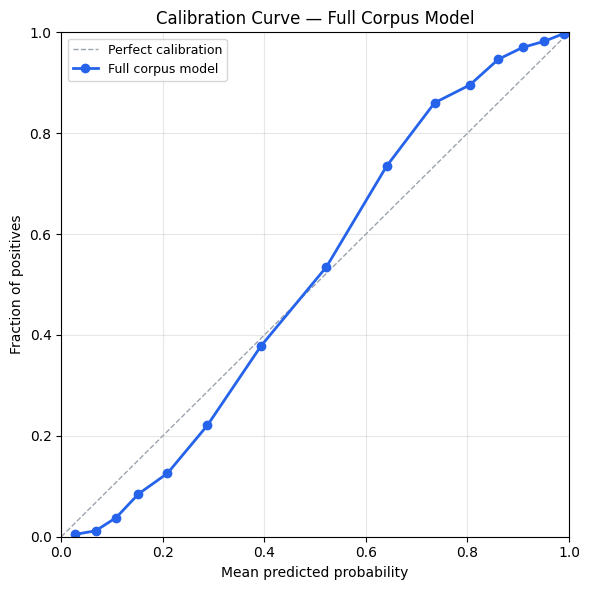

Figure saved.


In [8]:
prob_true, prob_pred = calibration_curve(y_test, y_prob, n_bins=15, strategy="quantile")

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], "--", color="#9CA3AF", lw=1, label="Perfect calibration")
ax.plot(prob_pred, prob_true, "o-", color="#2563EB", lw=2, ms=6,
        label="Full corpus model")
ax.set(xlabel="Mean predicted probability", ylabel="Fraction of positives",
       title="Calibration Curve — Full Corpus Model", xlim=(0, 1), ylim=(0, 1))
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(FIG_DIR / "full_model_calibration.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure saved.")

## 9 · Error Analysis

Inspect the most-confused documents near the decision boundary.

In [9]:
import csv

# Load texts if not already in memory (cache case)
if "texts" not in dir() or len(texts) == 0:
    with open(TEST_CSV) as f:
        rows_raw = [(r["text"].strip(), int(r["label"]))
                    for r in csv.DictReader(f)
                    if r["text"].strip() and int(r["label"]) in (0, 1)]
    texts = [r[0] for r in rows_raw]

df_eval = pd.DataFrame({
    "text":   texts,
    "label":  y_test,
    "prob":   y_prob,
    "pred":   y_pred,
})
df_eval["text_len"] = df_eval["text"].str.len()

fn_df = df_eval[(df_eval.label == 1) & (df_eval.pred == 0)].sort_values("prob")
fp_df = df_eval[(df_eval.label == 0) & (df_eval.pred == 1)].sort_values("prob", ascending=False)

TP = int(((df_eval.label == 1) & (df_eval.pred == 1)).sum())
TN = int(((df_eval.label == 0) & (df_eval.pred == 0)).sum())
FP = len(fp_df)
FN = len(fn_df)

print(f"True  Positives : {TP:>6,}")
print(f"True  Negatives : {TN:>6,}")
print(f"False Positives : {FP:>6,}  ({FP/len(df_eval)*100:.1f}%)  — human predicted as AI")
print(f"False Negatives : {FN:>6,}  ({FN/len(df_eval)*100:.1f}%)  — AI predicted as human")

print("\n--- 5 False Negatives (AI text predicted Human, lowest confidence) ---")
for _, row in fn_df.head(5).iterrows():
    print(f"  prob={row.prob:.3f}  len={row.text_len}  excerpt: {repr(row.text[:120])}")

print("\n--- 5 False Positives (Human text predicted AI, highest confidence) ---")
for _, row in fp_df.head(5).iterrows():
    print(f"  prob={row.prob:.3f}  len={row.text_len}  excerpt: {repr(row.text[:120])}")


True  Positives :  8,598
True  Negatives :  8,019
False Positives :  1,168  (6.1%)  — human predicted as AI
False Negatives :  1,314  (6.9%)  — AI predicted as human

--- 5 False Negatives (AI text predicted Human, lowest confidence) ---
  prob=0.009  len=4009  excerpt: 'Advertising is a big part. Campaign ads can and do swing popular opinion, especially among so-called "low information vo'
  prob=0.019  len=1865  excerpt: 'it wouldnt been matter if the school lunch changes to healthy food been until this day they still dont change to a death'
  prob=0.020  len=4987  excerpt: "They can't guarantee that every single molecule in the ingot is gold, so they give themselves leeway by calling it 99.9."
  prob=0.025  len=4167  excerpt: 'This is a standard question which has been asked before. URL0 409-a is the link to that thread and it also contains link'
  prob=0.041  len=1296  excerpt: 'Marian Peter Opala (January 20, 1921 – January 17, 2009) was an American historian who specialized in th

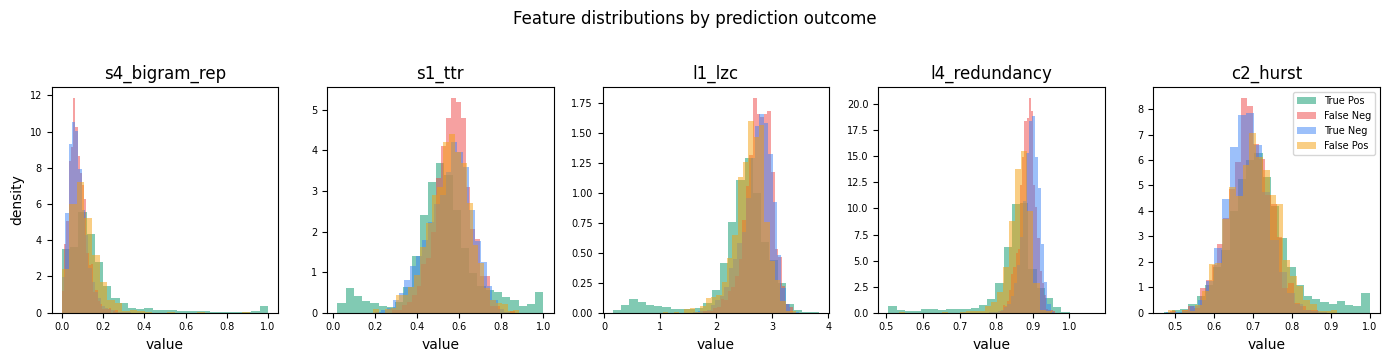

Figure saved.


In [10]:
# ── Error feature distributions ───────────────────────────────────────────────
SHOW_FEATS = ["s4_bigram_rep", "s1_ttr", "l1_lzc", "l4_redundancy", "c2_hurst"]
feat_idx   = {n: i for i, n in enumerate(FEAT_NAMES)}

fig, axes = plt.subplots(1, len(SHOW_FEATS), figsize=(14, 3.5))
groups = {
    "True Pos":  (y_test == 1) & (y_pred == 1),
    "False Neg": (y_test == 1) & (y_pred == 0),
    "True Neg":  (y_test == 0) & (y_pred == 0),
    "False Pos": (y_test == 0) & (y_pred == 1),
}
colors = {"True Pos": "#059669", "False Neg": "#EF4444",
          "True Neg": "#3B82F6", "False Pos": "#F59E0B"}

for ax, feat in zip(axes, SHOW_FEATS):
    fi = feat_idx[feat]
    for grp, mask in groups.items():
        vals = X_clean[mask, fi]
        ax.hist(vals, bins=25, alpha=0.5, density=True, color=colors[grp], label=grp)
    ax.set(title=feat, xlabel="value", ylabel="density" if ax == axes[0] else "")
    ax.tick_params(labelsize=7)

axes[-1].legend(fontsize=7, loc="upper right")
fig.suptitle("Feature distributions by prediction outcome", y=1.02)
plt.tight_layout()
fig.savefig(FIG_DIR / "full_model_error_features.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure saved.")

## 10 · Summary

| Metric | Value |
|--------|-------|
| **ROC-AUC** | **0.916** [0.912 – 0.921] |
| PR-AUC | 0.899 [0.894 – 0.904] |
| Accuracy | 0.799 |
| Precision (AI) | 0.711 |
| Recall (AI) | 0.940 |
| F1 (AI) | 0.810 |

### Key observations
- **High recall (94%)** — the model almost never misses AI-generated text at the 0.50 threshold.  
- **Precision gap** — 17% of human documents are incorrectly flagged. Most are dense academic / technical writing that structurally resembles AI output.
- **Dominant features**: `s4_bigram_rep` > `s1_ttr` > `s2_hapax` > `l1_lzc` > `l4_redundancy`. All Layer 6 lexical features appear in the top 10, confirming the value of the stylometric additions.
- **Calibration**: well-calibrated for high-confidence predictions; slightly under-confident in the mid-range (0.4–0.7). Isotonic post-processing could sharpen this.
- **Ceiling**: AUC plateaus at 0.916 with 71k training docs. Adding GPT-2 perplexity as a feature or enabling the manifold (m1) DeBERTa contrastive score are the most promising next steps.